In [13]:
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import cv2 as cv
from keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Conv2D, MaxPooling2D,Input, Flatten,Dropout

In [2]:
(x_train,y_train),(x_test,y_test) = tf.keras.datasets.mnist.load_data()

In [3]:
x_train.shape

(60000, 28, 28)

In [4]:
y_train.shape

(60000,)

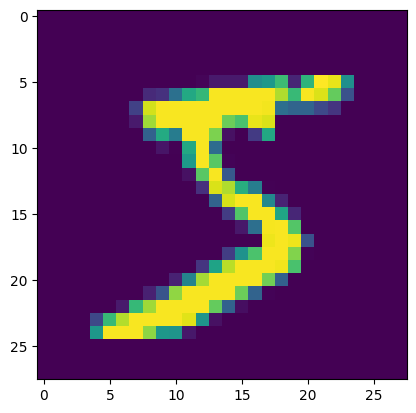

In [10]:
plt.imshow(x_train[0])

In [9]:
y_train

array([5, 0, 4, ..., 5, 6, 8], dtype=uint8)

In [11]:
x_train=x_train/255
x_test=x_test/255

In [14]:
model = Sequential([
    Conv2D(64, (3, 3), padding="same", activation="relu", input_shape=(28, 28, 1)),
    MaxPooling2D((2, 2)),
    
    Conv2D(32, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),

    Conv2D(30, (3, 3), padding="same", activation="relu"),
    MaxPooling2D((2, 2)),


    Flatten(),
    Dense(128, activation="relu"),
    Dropout(0.4),
    Dense(64, activation="relu"),
    Dropout(0.2),
    Dense(10, activation="softmax")
])

In [15]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 28, 28, 64)        640       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 14, 14, 64)       0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 14, 14, 32)        18464     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 7, 7, 32)         0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 7, 7, 30)          8670      
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 3, 3, 30)         0

In [16]:
model.compile(loss="sparse_categorical_crossentropy", optimizer="adam", metrics=["accuracy"])


In [17]:
history = model.fit(x_train,y_train, epochs=10,validation_split=0.2)

Epoch 1/10
1500/1500 [==============================] - 14s 4ms/step - loss: 0.3134 - accuracy: 0.9010 - val_loss: 0.0927 - val_accuracy: 0.9752
Epoch 2/10
1500/1500 [==============================] - 5s 4ms/step - loss: 0.0977 - accuracy: 0.9718 - val_loss: 0.0493 - val_accuracy: 0.9865
Epoch 3/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0736 - accuracy: 0.9796 - val_loss: 0.0411 - val_accuracy: 0.9889
Epoch 4/10
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0593 - accuracy: 0.9830 - val_loss: 0.0383 - val_accuracy: 0.9895
Epoch 5/10
1500/1500 [==============================] - 7s 5ms/step - loss: 0.0485 - accuracy: 0.9860 - val_loss: 0.0428 - val_accuracy: 0.9882
Epoch 6/10
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0423 - accuracy: 0.9880 - val_loss: 0.0418 - val_accuracy: 0.9887
Epoch 7/10
1500/1500 [==============================] - 6s 4ms/step - loss: 0.0365 - accuracy: 0.9892 - val_loss: 0.0378 - val_accuracy

In [18]:
model.predict(x_test)

313/313 [==============================] - 1s 2ms/step


array([[1.47382112e-17, 5.65145652e-10, 1.08969216e-08, ...,
        1.00000000e+00, 1.17616005e-14, 1.47941204e-09],
       [1.26636347e-14, 3.84694793e-12, 1.00000000e+00, ...,
        3.16751681e-12, 1.16521427e-14, 1.53627143e-17],
       [8.35936931e-10, 9.99995947e-01, 1.08653175e-07, ...,
        3.70139105e-06, 1.38702172e-09, 1.16679217e-08],
       ...,
       [1.07214514e-20, 4.60432287e-17, 4.15692834e-18, ...,
        2.06434313e-14, 1.60759389e-16, 7.06509829e-13],
       [9.00276988e-12, 1.88371166e-14, 5.09139328e-16, ...,
        5.27897333e-13, 6.86649670e-09, 9.59399782e-10],
       [1.15916132e-09, 4.32432432e-12, 5.91837235e-14, ...,
        3.27734650e-16, 5.83172011e-10, 9.52846759e-15]], dtype=float32)

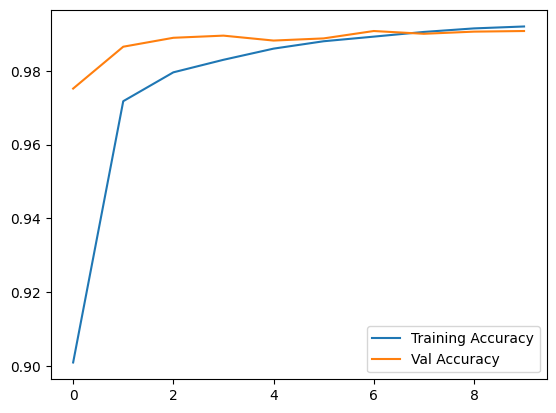

In [19]:
plt.plot(history.history["accuracy"],label='Training Accuracy')
plt.plot(history.history["val_accuracy"],label='Val Accuracy')
plt.legend()

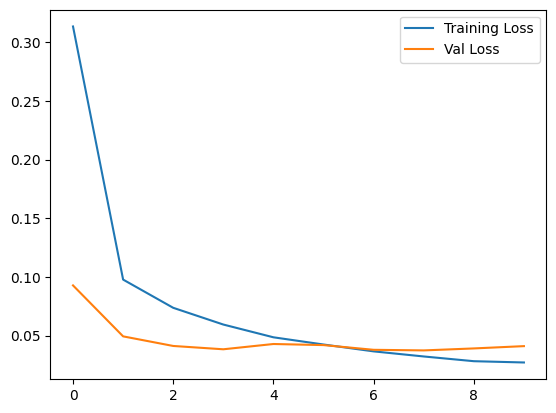

In [20]:
plt.plot(history.history["loss"],label='Training Loss')
plt.plot(history.history["val_loss"],label='Val Loss')
plt.legend()


In [21]:
y_pred= model.predict(x_test)

313/313 [==============================] - 1s 2ms/step


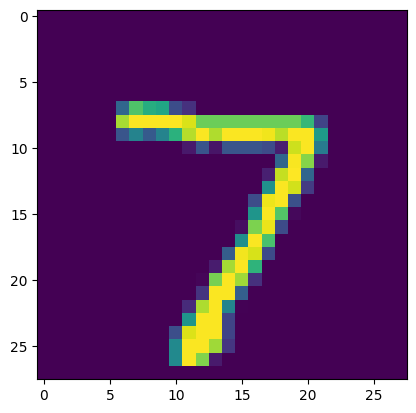

In [22]:
plt.imshow(x_test[0])

In [25]:
y_pred[0].argmax()

7